# Import libraries and load the dataset

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

pd.set_option("display.max_columns", None)

df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (44988, 14)


,Age,Gender,Education,Person Income,Employee Experience,Home Ownership,Loan Amount,Loan Intent,Credit History,Credit Score,Previous Loan,Loan Status,Loan_to_Income,Log_Person_Income
0,22,female,Master,71948,0,RENT,35000,PERSONAL,3,561,No,1,0.486462,11.183713
1,21,female,High School,12282,0,OWN,1000,EDUCATION,2,504,Yes,0,0.081420,9.415971
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,3,635,No,1,0.442193,9.428592
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,2,675,No,1,0.438855,11.286702
4,24,male,Master,66135,1,RENT,35000,MEDICAL,4,586,No,1,0.529221,11.099469


# Defination features and split the data

In [2]:
target = "Loan Status"

numeric_features = [
    "Age",
    "Employee Experience",
    "Log_Person_Income",
    "Loan Amount",
    "Credit History",
    "Credit Score",
    "Loan_to_Income"
]

categorical_features = [
    "Gender",
    "Education",
    "Home Ownership",
    "Loan Intent",
    "Previous Loan"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (35990, 12)
Testing features: (8998, 12)

Training target distribution:
Loan Status
0    0.7777
1    0.2223
Name: proportion, dtype: float64

Testing target distribution:
Loan Status
0    0.7777
1    0.2223
Name: proportion, dtype: float64


# Building the preprocessing pipeline

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

# Defination the models

In [4]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=20,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Models to compare:")
for name in models:
    print("-", name)

Models to compare:
- Logistic Regression
- Decision Tree
- Random Forest
- HistGradientBoosting


The Decision Tree has limits on its depth and leaf size to reduce overfitting. Random Forest combines many trees, while HistGradientBoosting builds trees sequentially to improve predictive performance.

# Train and evaluate all models

In [5]:
results = []
trained_models = {}

for name, classifier in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(
            y_test, y_prob
        ),
        "Training Time (seconds)": training_time
    })

    trained_models[name] = pipeline

comparison_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1 Score",
    "ROC-AUC", "Average Precision"
]

comparison_df[metric_columns] = (
    comparison_df[metric_columns].round(4)
)

comparison_df["Training Time (seconds)"] = (
    comparison_df["Training Time (seconds)"].round(2)
)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(comparison_df)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training HistGradientBoosting...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision,Training Time (seconds)
0,HistGradientBoosting,0.9025,0.8529,0.6785,0.7558,0.9573,0.8856,1.14
1,Random Forest,0.8944,0.8414,0.6470,0.7315,0.9520,0.8722,3.69
2,Decision Tree,0.8861,0.8690,0.5740,0.6914,0.9430,0.8391,0.17
3,Logistic Regression,0.8723,0.7267,0.6820,0.7036,0.9357,0.8116,0.27


# Saving the results

In [6]:
comparison_df.to_csv(
    "../reports/model_comparison_results.csv",
    index=False
)

print("Results saved to reports/model_comparison_results.csv")

Results saved to reports/model_comparison_results.csv


# Plotting the model comparison

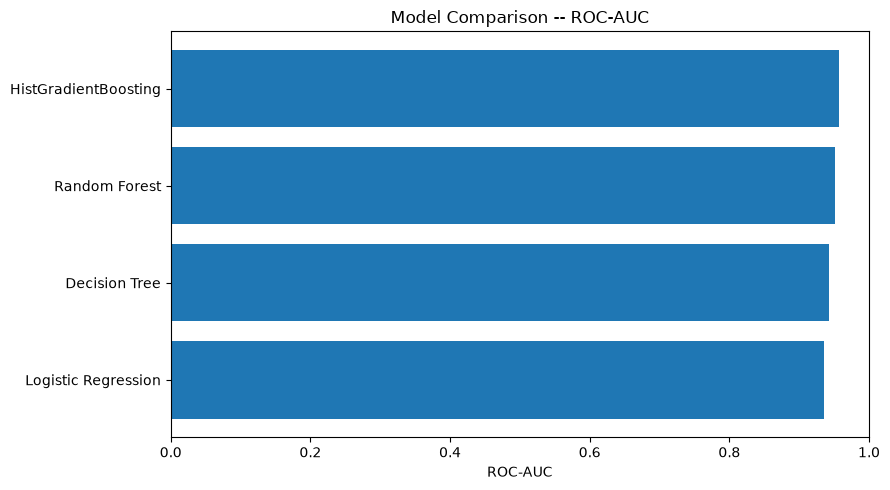

In [8]:
plot_df = comparison_df.sort_values(
    "ROC-AUC",
    ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(plot_df["Model"], plot_df["ROC-AUC"])
plt.xlabel("ROC-AUC")
plt.title("Model Comparison -- ROC-AUC")
plt.xlim(0, 1)
plt.grid(False)
plt.tight_layout()
plt.show()

### Model Comparison Results

Four classification algorithms were evaluated using the same stratified training and test sets. HistGradientBoosting achieved the strongest overall results, with an accuracy of 90.25%, an F1-score of 0.7558, a ROC-AUC of 0.9573, and an average precision of 0.8856. Random Forest ranked second in ROC-AUC at 0.9520, followed by Decision Tree at 0.9430 and Logistic Regression at 0.9357.

Compared with the Logistic Regression baseline, HistGradientBoosting improved accuracy by 2.97 percentage points and F1-score by 5.22 percentage points. However, its class 1 recall was 67.85%, slightly below the baseline recall of 68.20%. This indicates that the improvement in overall performance did not translate into improved identification of every class 1 observation.

HistGradientBoosting is therefore selected as the leading candidate for further evaluation. Its classification threshold, probability calibration, and decision-making implications should be examined before finalising the model for the loan decisioning system.